# Multi-Factor Equity Screener

This notebook ranks US stocks on five factor categories (value, quality, momentum, growth and low volatility), then backtests the price-based factors to see whether they predicted returns. My result: they did not.

**How to use it**

1. Click **Runtime > Run all** (in Jupyter: **Run > Run All Cells**).
2. Wait one to two minutes. The first run downloads prices and fundamentals from Yahoo Finance.
3. Scroll down. Each step has a short explanation under it.

To try something else, change the two settings in step 2: the stock universe (`test50` is a quick 50-stock set, `sp500` is the full index and takes much longer) and the ticker for the single-stock report.

**Read this first.** Fundamentals from Yahoo are current values, not point-in-time, so the historical backtest uses only price factors (12-1 momentum, 6-month momentum, 60-day volatility and beta). The stock lists are today's, which builds in survivorship bias. Sharpe ratios use a 0% risk-free rate. This is a research project, not investment advice.

The numbers below come from a fresh download with prices ending 5 Oct 2026. Yahoo revises its data, so they can differ in the last digit from the saved tables in `outputs/test50/`. Those tables are the reference. Running this notebook does not overwrite them.

## 1. Set up

This cell gets the code and installs what is missing. In Colab it adds only `yfinance`, so you will not be asked to restart the runtime.

In [1]:
#@title Set up (runs automatically) { display-mode: "form" }
import os
import subprocess
import sys

REPO_URL = "https://github.com/FleximusRex/Finance-equity-scanner.git"

if "google.colab" in sys.modules:
    if not os.path.exists("Finance-equity-scanner"):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("Finance-equity-scanner")
    # Colab already has pandas, numpy, scipy, matplotlib, plotly and pyarrow.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "yfinance", "lxml"],
                   check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # running locally: start from the repo root
sys.path.insert(0, os.getcwd())
print("Ready. Working folder:", os.path.basename(os.getcwd()))

Ready. Working folder: Finance-equity-scanner


## 2. Choose your settings

In [2]:
UNIVERSE = "test50"  #@param ["test50", "sp500"]
TICKER = "AAPL"  #@param {type:"string"}

In [3]:
import io
import logging
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

from src import backtest, config, rank, visualization
from src.data_loader import load_prices
from src.report import show_report, stock_report
from src.universe import get_universe

config.set_universe(UNIVERSE)
config.CHARTS_DIR = config.CACHE_DIR / "notebook_charts"  # keep the saved charts untouched

logging.basicConfig(level=logging.INFO, format="%(message)s")
logging.getLogger("yfinance").setLevel(logging.CRITICAL)
print(f"Universe: {UNIVERSE} ({len(get_universe())} stocks)")

Universe: test50 (50 stocks)


## 3. Today's ranking

Every stock gets a score from 12 metrics in five categories. Each metric is winsorized (extreme values clipped), converted to a z-score, and averaged within its category. The composite is a weighted average of the category scores.

- **Composite**: higher is better. A score of 1 means about one standard deviation above the average stock.
- **Quintile**: 1 is the best 20% of stocks, 5 is the worst 20%.
- **Momentum and LowVol** are category scores. A negative LowVol means the stock is more volatile than average.

In [4]:
rankings = rank.build_rankings()
columns = ["Ticker", "Company", "Sector", "Composite", "Quintile", "Value", "Quality",
           "Momentum", "Growth", "LowVol"]
display(rankings[columns].head(10).round(2).reset_index(drop=True))

,Ticker,Company,Sector,Composite,Quintile,Value,Quality,Momentum,Growth,LowVol
0,ABBV,AbbVie Inc.,Healthcare,0.83,1,-0.34,0.84,0.63,3.12,0.76
1,NVDA,NVIDIA Corporation,Technology,0.75,1,-0.04,1.26,0.90,2.38,-1.38
2,CVX,Chevron Corporation,Energy,0.54,1,0.82,-0.05,0.51,0.86,0.95
3,COP,ConocoPhillips,Energy,0.51,1,0.96,-0.01,0.45,0.61,0.66
4,CSCO,"Cisco Systems, Inc.",Technology,0.50,1,-0.06,0.25,1.89,0.26,-0.56
5,XOM,ExxonMobil Holdings Corporation,Energy,0.40,1,0.57,-0.22,0.53,0.62,0.92
6,LLY,Eli Lilly and Company,Healthcare,0.37,1,-0.74,0.83,1.00,0.53,0.14
7,AAPL,Apple Inc.,Technology,0.27,1,-0.62,0.97,0.87,-0.20,-0.04
8,V,Visa Inc.,Financial Services,0.27,1,-0.39,0.97,0.34,-0.14,0.59
9,MA,Mastercard Incorporated,Financial Services,0.25,1,-0.40,1.35,-0.09,-0.12,0.55


The top of a ranking like this is often dominated by stocks with extreme recent momentum. Treat it as a screen for further research, not a list of recommendations.

## 4. Did the factors predict returns?

Each month I ranked every stock using only data available at that date, split them into five equal groups, and held each group for a month. Q1 is the top-ranked group. Costs are 10 bps per side.

The backtest uses only the price factors (momentum and low volatility), for the reason in the note at the top.

In [5]:
prices = load_prices([*get_universe(), config.BENCHMARK])
dates = backtest.rebalance_dates(prices.index)[:-1]
signals = backtest.signals_through_time(prices, dates)
monthly, ic = backtest.backtest_signal(prices, signals["composite"])
table, ic_summary = backtest.summarize(monthly, ic)

portfolios = {"Top 20% (Q1)": "Q1_net", "Bottom 20% (Q5)": "Q5_net",
              "Long-short (Q1 minus Q5)": "LS_net", "Equal-weight universe": "EW_net",
              "SPY": "SPY"}
results = pd.DataFrame({
    name: {"Return per year": f"{table.loc[key, 'CAGR']:.1%}",
           "Sharpe ratio": f"{table.loc[key, 'Sharpe']:.2f}",
           "Worst drawdown": f"{table.loc[key, 'MaxDD']:.1%}"}
    for name, key in portfolios.items()}).T
print(f"{len(monthly)} monthly rebalances, {monthly.index[0]:%b %Y} to {monthly.index[-1]:%b %Y}")
display(results)

142 monthly rebalances, Dec 2014 to Sep 2026


,Return per year,Sharpe ratio,Worst drawdown
Top 20% (Q1),20.1%,1.18,-13.2%
Bottom 20% (Q5),16.8%,0.82,-35.9%
Long-short (Q1 minus Q5),-1.6%,0.03,-45.8%
Equal-weight universe,18.0%,1.24,-20.0%
SPY,13.7%,0.94,-23.9%


How to read this: compare **Q1** with the **equal-weight universe**, not with SPY. Both hold today's index members, so both benefit from survivorship bias, and the equal-weight basket needs no factor model at all. If Q1 is not clearly better than that basket, the factors added little. The long-short row is the pure factor bet, buying Q1 and shorting Q5.

In [6]:
names = {"mom_12_1": "12-1 month momentum", "ret_6m": "6-month momentum",
         "vol_60d": "60-day volatility (low is better)", "beta": "Beta (low is better)",
         "composite": "Composite (momentum + low vol)"}
tests = backtest.factor_tests(prices, signals)
verdict = pd.DataFrame({
    "Average IC": tests["IC_mean"].round(3),
    "t-stat": tests["IC_t"].round(2),
    "p-value": tests["IC_p"].round(3),
    "Significant at 5%?": ["yes" if p < 0.05 else "no" for p in tests["IC_p"]],
}).rename(index=names)
display(verdict)
best = tests["IC_p"].min()
print(f"Smallest p-value: {best:.3f}. "
      + ("At least one factor is significant at 5%." if best < 0.05
         else "No factor is significant at the 5% level."))

,Average IC,t-stat,p-value,Significant at 5%?
factor,,,,
12-1 month momentum,0.014,0.60,0.552,no
6-month momentum,0.029,1.37,0.173,no
60-day volatility (low is better),-0.045,-1.85,0.067,no
Beta (low is better),-0.055,-1.88,0.062,no
Composite (momentum + low vol),0.003,0.14,0.887,no


Smallest p-value: 0.062. No factor is significant at the 5% level.


**What the columns mean.** The IC (information coefficient) is the correlation between a factor's ranking and the next month's returns, measured each month and averaged. An IC of 0 means no predictive power. The t-stat and p-value test whether the average IC is really different from zero. A p-value below 0.05 is the usual bar, and I tested several factors without correcting for that, so even a value like 0.06 is weak evidence at best.

Low volatility showed a negative IC, the wrong sign: riskier stocks did better over this period. That fits a long bull market, and survivorship bias inflates it.

## 5. Charts

The images are shrunk here to keep the notebook light. Full-size charts for the S&P 500 run are in `outputs/sp500/charts/` in the repository.

saved 7 charts -> data/cache/notebook_charts


**The 20 highest composite scores.**

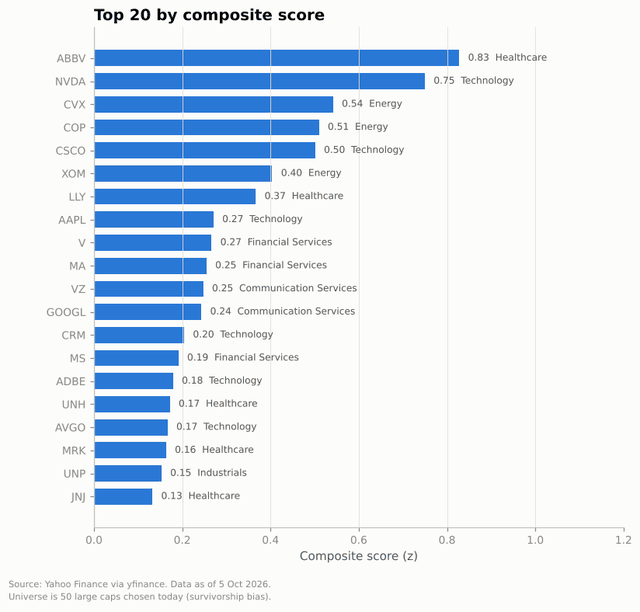

**Category scores for those 20 stocks. Blue is strong, red is weak.**

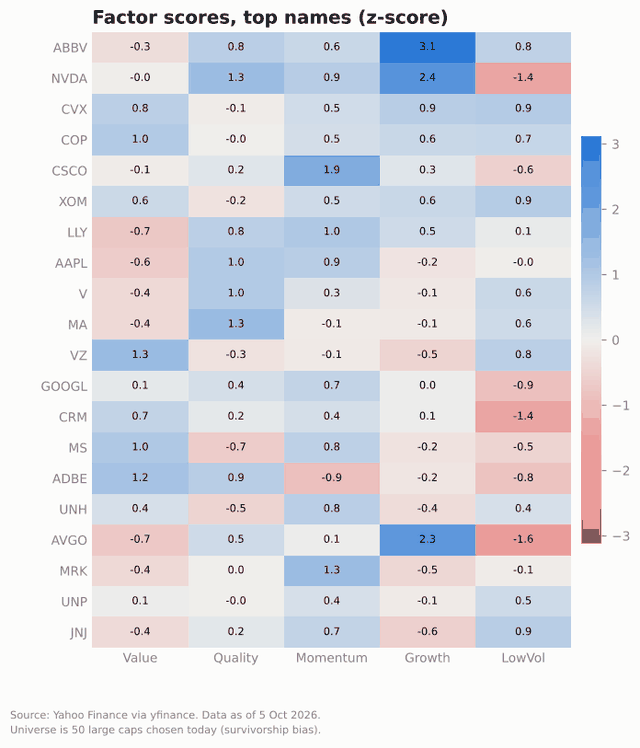

**Growth of $1 in each quintile portfolio, after costs.**

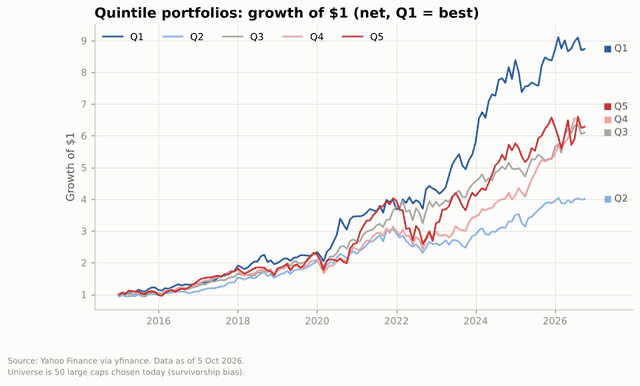

**Q1, the long-short portfolio, the equal-weight universe and SPY, with drawdowns below.**

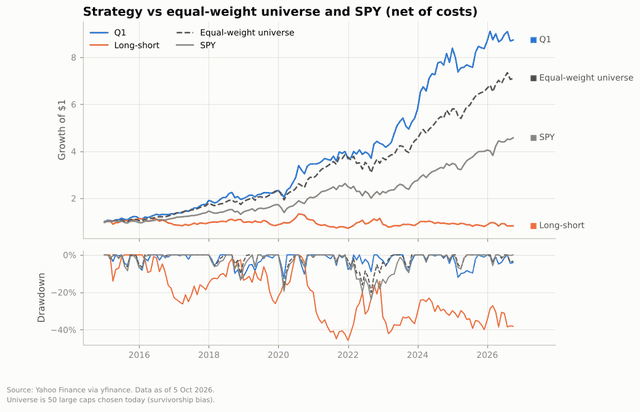

**Rolling 12-month Sharpe ratio. It swings a lot, which is a reason for caution.**

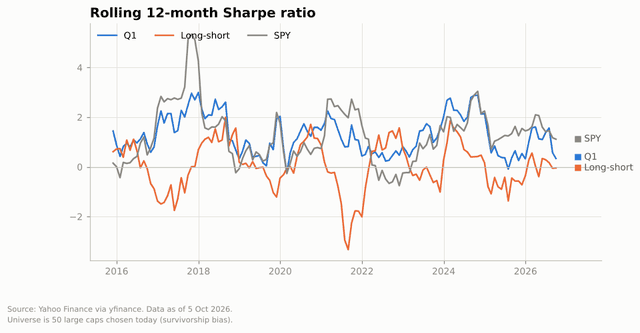

**Monthly rank IC. Bars above zero mean the ranking worked that month. Mean IC is near zero.**

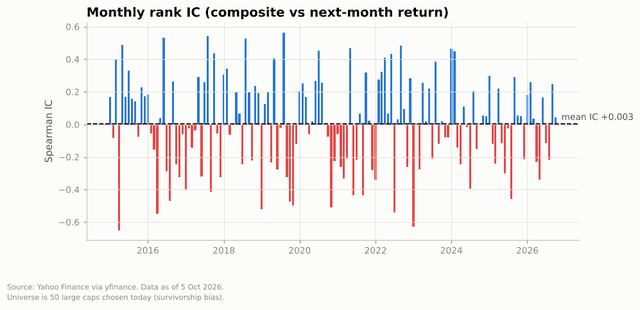

**Where the top quintile is concentrated by sector, against the whole universe.**

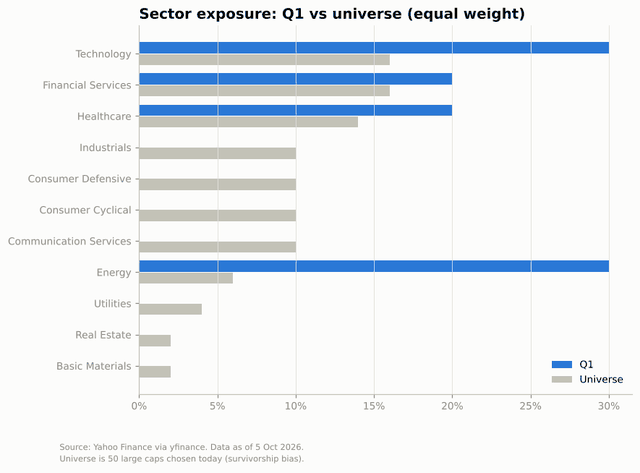

In [7]:
def show_small(path, width=640):
    image = PILImage.open(path).convert("RGB")
    image = image.resize((width, round(image.height * width / image.width)), PILImage.LANCZOS)
    buffer = io.BytesIO()
    image.quantize(128).save(buffer, format="PNG", optimize=True)
    display(Image(data=buffer.getvalue()))


captions = {
    "01": "The 20 highest composite scores.",
    "02": "Category scores for those 20 stocks. Blue is strong, red is weak.",
    "03": "Growth of $1 in each quintile portfolio, after costs.",
    "04": "Q1, the long-short portfolio, the equal-weight universe and SPY, with drawdowns below.",
    "05": "Rolling 12-month Sharpe ratio. It swings a lot, which is a reason for caution.",
    "06": "Monthly rank IC. Bars above zero mean the ranking worked that month. Mean IC is near zero.",
    "07": "Where the top quintile is concentrated by sector, against the whole universe.",
}
for path in visualization.make_all(rankings, monthly.assign(IC=ic)):
    display(Markdown(f"**{captions[path.name[:2]]}**"))
    show_small(path)

## 6. Look up one stock

Change `TICKER` in step 2 and rerun this cell. The ticker must be in the universe you chose. The two interactive charts show in Colab and Jupyter but not in GitHub's notebook preview.

In [8]:
try:
    show_report(stock_report(TICKER.upper(), rankings=rankings))
except ValueError:
    print(f"{TICKER} is not in the {UNIVERSE} universe. Pick another ticker or switch the universe.")

AAPL - Apple Inc. (Technology)
Composite +0.27 | percentile 86 | quintile 1 | sector rank 3/8
Category z-scores: Value -0.62  Quality +0.97  Momentum +0.87  Growth -0.20  LowVol -0.04
              AAPL  SectorMedian
Ret1M        0.014         0.016
Ret6M        0.288         0.269
Ret12M       0.299         0.053
FCFYield     0.021         0.020
EV_EBITDA   30.116        18.641
Volatility   0.273         0.392
Beta         0.684         1.009
AAPL ranks in the 86th percentile of the 50-stock universe (quintile 1) and #3 of 8 in Technology. Its strongest factor is Quality (z = +0.97) and its weakest is Value (z = -0.62). This is a descriptive factor profile, not a recommendation.


## Where to go next

- The [README](https://github.com/FleximusRex/Finance-equity-scanner#readme) has the S&P 500 results.
- [docs/methodology.md](https://github.com/FleximusRex/Finance-equity-scanner/blob/main/docs/methodology.md) explains the factors, the backtest and the limitations in full.
- The [dashboard](https://fleximusrex.github.io/Finance-equity-scanner/) lets you browse the rankings and results.